## Supplementary: what linear probes do and do not tell us

This notebook collects the probing and steering experiments that sit behind the
main pub's claim that decodability reports what is *encoded*, not what is
*computed with*. It is exploratory supporting material, not part of the main
argument, and several of its results are negative.

Five things are established here, in order:

1. **The probing protocol is in-sample, and it matters where.** Liu et al. fit and
   score their probes on the same activations. Reproduced faithfully, that is the
   right thing to do for comparability — but scored out-of-sample the phase
   transition *sharpens*, because in-sample fitting inflates the weak readouts
   and leaves the strong ones untouched.
2. **The force encoding in the noisy model is real and non-trivial.** It survives
   a held-out split at $R^2 \approx 0.99$, sits far above a shuffled-label null,
   and is not recoverable from the raw input coordinates.
3. **The $R^2$ is bought in directions the model barely varies along.** At the
   final layernorm, five of thirty-two directions carry 99% of the activation
   variance; a probe restricted to them recovers $R^2 = 0.23$, and the headline
   number needs components two to four orders of magnitude smaller. The genuinely
   Newtonian noiseless model, by contrast, has the force far more available in the
   leading components. This is the mechanical reconciliation of a near-perfect
   probe with a model that is not computing a force.
4. **It is actionable, but only when scored against the right baseline.** An
   intervention along the force direction, applied to the residual stream at
   every layer, propagates to the final layer and moves the prediction *in the
   direction a genuine increase in gravity would* — cosine $+0.97$ with that
   counterfactual, against zero for random directions of matched norm. Judged
   instead by displacement size, the same intervention looks like a failure;
   noise moves the prediction *further*, only nowhere in particular.
5. **And a successful steering result still does not identify the mechanism.**
   Scored properly, the intervention passes: efficacious, directionally
   specific, propagating, multi-layer. It nevertheless fails to distinguish a
   Newtonian force integrator from the circular heuristic the main text's ELM
   analysis actually finds, because the two predict displacements along nearly
   the same direction and the magnitude — the one statistic that would separate
   them — is swamped by what random perturbations of matched norm produce.

The fourth point carries a methodological warning that took us several wrong
turns to find. Effect size against a random-perturbation floor is the wrong
statistic for a steering experiment: it rewards displacement and is blind to
whether the displacement goes anywhere sensible. The comparison that matters is
against an explicit counterfactual — what the prediction *should* be if the
intervention had taken effect — which is the criterion Nanda et al. (2023) use
for the Othello board state, and which reverses the sign of our conclusion.

The fifth is the reason the steering material is supplementary rather than a result.
The steering experiment is worth running and worth reporting, but on its own it
underdetermines the mechanism it appears to probe.

In [1]:
#| code-fold: true
#| output: false
import io, contextlib, numpy as np, torch, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

from analysis.model import load_from_checkpoint
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import (setup_activation_hooks, collect_activations,
                              make_probe_windows)

torch.set_default_dtype(torch.float64)

CKPT_DIR = './checkpoints/kepler_cv_blocksize_elm'
NUM_TRAJ = 10000          # the transformer's train half is trajectories [:10000]
TEST_OFF = NUM_TRAJ       # everything below index 10000 was seen during training
SEED     = 0
DT_SUPP  = 20/99          # true sample spacing of the trajectories

def load(noise, block_size):
    with contextlib.redirect_stdout(io.StringIO()):
        mdl, _ = load_from_checkpoint(
            f'{CKPT_DIR}/model_block_size_{block_size}_num_trajectories_'
            f'{NUM_TRAJ}_noise_scale_{noise}.pt', device='cpu')
    mdl.eval()
    return mdl

def probe_activations(mdl, trajs, ops, block_size, n_probe=1000, seed=SEED):
    """Windows + every hooked activation + the force targets, as the pub's pipeline does."""
    with contextlib.redirect_stdout(io.StringIO()):
        wnd, tidx = make_probe_windows(trajs, ops, block_size, n_probe, seed)
        hooks, act = setup_activation_hooks(mdl)
        _, gforce = collect_activations(mdl, torch.tensor(wnd), None, act)
    for h in hooks:
        h.remove()
    return wnd, tidx, {k: v[:, -1, :].cpu().numpy() for k, v in act.items()}, gforce

def r2_in_out(X, y, seed=0):
    """In-sample and held-out R^2 for a linear probe on the same data."""
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, random_state=seed)
    ins = r2_score(y, LinearRegression().fit(X, y).predict(X))
    out = r2_score(yte, LinearRegression().fit(Xtr, ytr).predict(Xte))
    return ins, out

## 1. In-sample versus held-out probing

Liu et al.'s `run_linear_probes` fits a `LinearRegression` and scores it on the
same activations, with no split, on the *training* trajectories, taking the best
result over thirteen layers. Reproducing that is the right call for
comparability — the main pub's phase-transition figure does exactly this — but it
is worth knowing what the protocol costs.

Below, the same probes scored both ways. The Newtonian targets are the force
magnitude and components; the Keplerian ones are the semi-major and semi-minor
axes and the Laplace–Runge–Lenz vector.

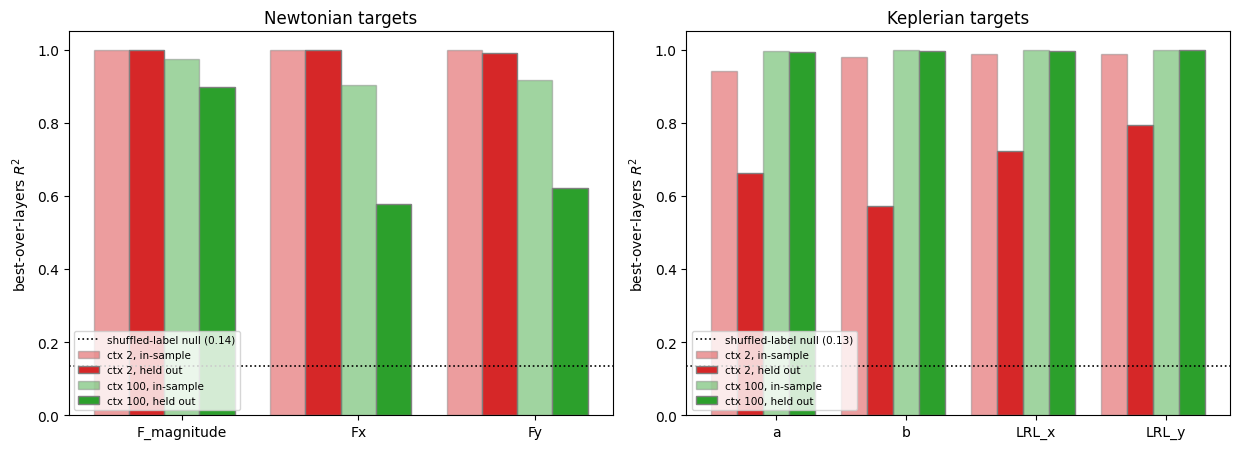

target        ctx  in-sample  held out  shuffled
F_magnitude     2      1.000     0.999     0.134
Fx              2      1.000     0.999     0.146
Fy              2      1.000     0.990     0.164
a               2      0.942     0.661     0.134
b               2      0.981     0.573     0.129
LRL_x           2      0.988     0.724     0.143
LRL_y           2      0.989     0.793     0.134
F_magnitude   100      0.973     0.897     0.136
Fx            100      0.903     0.578     0.134
Fy            100      0.916     0.623     0.118
a             100      0.997     0.994     0.126
b             100      0.999     0.997     0.122
LRL_x         100      0.999     0.997     0.150
LRL_y         100      0.999     0.998     0.152


In [2]:
#| label: fig-supp-insample
#| fig-cap: "Best-over-layers linear-probing R^2 for each target, scored in-sample (as in the original protocol) and on a held-out half of the same windows. Dotted line: the in-sample R^2 obtained after shuffling the labels, i.e. the level the protocol reaches on pure noise. In-sample fitting leaves the dominant world model's variables untouched and inflates the subordinate one's, so the phase transition is sharper out-of-sample than in."
#| code-fold: true
NEWTON = ['F_magnitude', 'Fx', 'Fy']
KEPLER = ['a', 'b', 'LRL_x', 'LRL_y']

with contextlib.redirect_stdout(io.StringIO()):
    trajs_tr = np.asarray(load_trajectories('data_cv', num_trajectories_needed=NUM_TRAJ))
    ops_tr   = load_orbital_params('data_cv', num_trajectories_needed=NUM_TRAJ)

rows = {}
rng = np.random.default_rng(SEED)
for bs in (2, 100):
    mdl = load(0.1, bs)
    wnd, tidx, acts, gforce = probe_activations(mdl, trajs_tr, ops_tr, bs)
    B = wnd.shape[0]
    targets = {t: gforce[t].reshape(B, -1)[:, -1] for t in NEWTON}
    targets.update({t: np.array([ops_tr[i][t] for i in tidx]) for t in KEPLER})
    for t, y in targets.items():
        ins = out = nul = -np.inf
        yperm = rng.permutation(y)
        for X in acts.values():
            i_, o_ = r2_in_out(X, y)
            ins, out = max(ins, i_), max(out, o_)
            nul = max(nul, r2_score(yperm, LinearRegression().fit(X, yperm).predict(X)))
        rows[(bs, t)] = (ins, out, nul)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, (title, tgts) in zip(axes, [('Newtonian targets', NEWTON),
                                    ('Keplerian targets', KEPLER)]):
    x = np.arange(len(tgts)); w = 0.2
    for j, (bs, colour) in enumerate([(2, 'tab:red'), (100, 'tab:green')]):
        ax.bar(x + (j - 1) * 2 * w, [rows[(bs, t)][0] for t in tgts], w,
               color=colour, alpha=0.45, edgecolor='grey',
               label=f'ctx {bs}, in-sample')
        ax.bar(x + (j - 1) * 2 * w + w, [rows[(bs, t)][1] for t in tgts], w,
               color=colour, edgecolor='grey', label=f'ctx {bs}, held out')
    nul = np.median([rows[(bs, t)][2] for bs in (2, 100) for t in tgts])
    ax.axhline(nul, ls=':', color='k', lw=1.2, label=f'shuffled-label null ({nul:.2f})')
    ax.set_xticks(x); ax.set_xticklabels(tgts); ax.set_ylim(0, 1.05)
    ax.set_ylabel(r'best-over-layers $R^2$'); ax.set_title(title)
    ax.legend(fontsize=7.5, loc='lower left')
fig.tight_layout(); plt.show()

print(f'{"target":12s} {"ctx":>4s} {"in-sample":>10s} {"held out":>9s} {"shuffled":>9s}')
for (bs, t), (i_, o_, n_) in rows.items():
    print(f'{t:12s} {bs:4d} {i_:10.3f} {o_:9.3f} {n_:9.3f}')

The in-sample protocol does not distort the *dominant* world model at either
context length — the force variables at context 2 and the orbital-geometry
variables at context 100 barely move when scored out-of-sample. What it inflates
is the *subordinate* set. So the reading that every variable stays decodable
above $R^2 = 0.9$ at both context lengths, and that the transition is a shift in
emphasis rather than a switch, is an artifact of the protocol; held out, it is
much closer to a switch.

The shuffled-label null is the other half of the point. Fitting and scoring on
the same data reaches an $R^2$ well above zero on pure noise, which is the
quantity a reader needs in order to judge whether a gap between two $R^2$ values
means anything.

## 2. The force encoding is real, and it is not in the input

Before treating the context-2 force result as something to explain, it is worth
ruling out the trivial reading: that $|F| = 1/|r_t|^2$ is simply a smooth
function of an input the probe can see. For the force *magnitude* it is not: a probe on the raw
coordinates recovers essentially none of it, and $|F|$ only becomes decodable
after the first MLP. The *components* are a weaker case — $F_x \approx -x/r^3$
does correlate with $x$, so a raw-coordinate probe reaches about $0.5$ on them —
which is why the magnitude is the cleaner evidence that something is being
computed rather than read off.

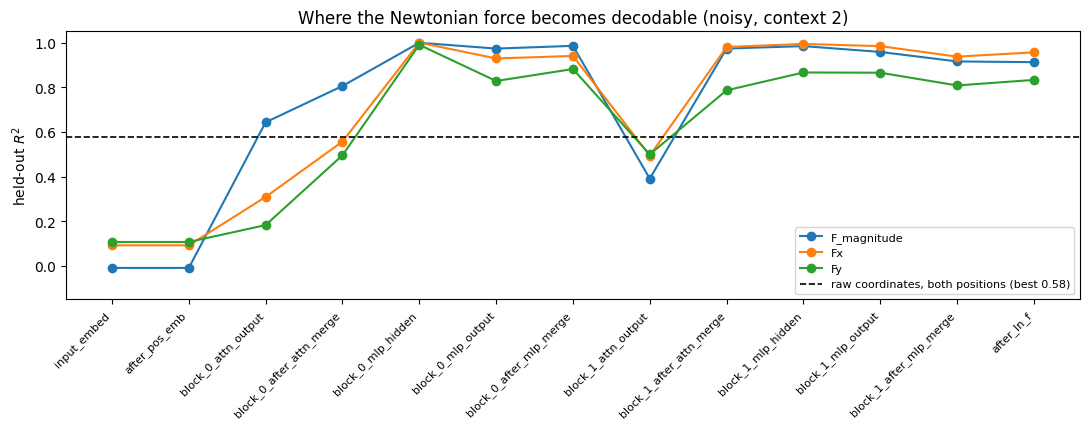

raw-coordinate baselines (held out)
  both positions: F_magnitude -0.141   Fx +0.479   Fy +0.579
  r_t alone     : F_magnitude -0.009   Fx +0.092   Fy +0.107


In [3]:
#| label: fig-supp-layers
#| fig-cap: "Held-out probing R^2 for the Newtonian force variables at every hooked site in the noisy context-2 model, in execution order, with a probe on the raw input coordinates as a baseline. The force is not present in the input embedding and appears abruptly at the first MLP hidden layer."
#| code-fold: true
mdl2 = load(0.1, 2)
wnd, tidx, acts, gforce = probe_activations(mdl2, trajs_tr, ops_tr, 2)
B = wnd.shape[0]
Y = {t: gforce[t].reshape(B, -1)[:, -1] for t in NEWTON}

ORDER = ['input_embed', 'after_pos_emb',
         'block_0_attn_output', 'block_0_after_attn_merge', 'block_0_mlp_hidden',
         'block_0_mlp_output', 'block_0_after_mlp_merge',
         'block_1_attn_output', 'block_1_after_attn_merge', 'block_1_mlp_hidden',
         'block_1_mlp_output', 'block_1_after_mlp_merge', 'after_ln_f']

fig, ax = plt.subplots(figsize=(11, 4.4))
for t, colour in zip(NEWTON, ['tab:blue', 'tab:orange', 'tab:green']):
    ys = [r2_in_out(acts[s], Y[t])[1] for s in ORDER]
    ax.plot(range(len(ORDER)), ys, 'o-', color=colour, label=t)
raw_r2  = {t: r2_in_out(wnd.reshape(B, -1), Y[t])[1] for t in NEWTON}   # both positions
raw_rt  = {t: r2_in_out(wnd[:, -1, :], Y[t])[1] for t in NEWTON}        # r_t alone
ax.axhline(max(raw_r2.values()), ls='--', color='k', lw=1.2,
           label=f'raw coordinates, both positions (best {max(raw_r2.values()):.2f})')
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels(ORDER, rotation=45, ha='right', fontsize=8)
ax.set_ylabel(r'held-out $R^2$'); ax.set_ylim(-0.15, 1.05)
ax.set_title('Where the Newtonian force becomes decodable (noisy, context 2)')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

print('raw-coordinate baselines (held out)')
print('  both positions: ' + '   '.join(f'{t} {v:+.3f}' for t, v in raw_r2.items()))
print('  r_t alone     : ' + '   '.join(f'{t} {v:+.3f}' for t, v in raw_rt.items()))

So for the force magnitude the model computes something the input does not hand
it. Two consequences.
The main pub's mechanistic claim is *not* that the probe is a false positive —
the encoding is genuine — but that the model does not compute with it. And any
steering attempt has a real target to aim at.

## 3. The $R^2$ is real, but it lives where the model barely varies

Sections 1 and 2 leave the force encoding standing: held-out $R^2 \approx 0.999$,
far above a shuffled null, and not recoverable from the raw coordinates. That is
the fact the main text has to accommodate, so it is worth asking *where* in the
representation it sits.

We ask at the final layernorm, `after_ln_f`, because it is the one site where "what
the model uses" is exactly defined. The output head is linear and bias-free, so the
prediction is $\hat{\mathbf r}_{t+1} = W_{\text{head}}\,\mathrm{ln_f}$ with no
remainder — the cell below checks the reconstruction to machine zero. A subspace
decomposition of `ln_f` therefore passes through the head exactly and additively,
which is not true at an MLP hidden layer or a mid-block residual, where any claim
about what is "used" needs an extra argument about what the remaining layers do.

Take the SVD of the centred activations over held-out windows and probe $|F|$ from
the top-$k$ principal components. Two notes on the construction:

- **Refitting and truncating are the same operation here.** PCA yields uncorrelated
  coordinates, so the OLS coefficient on each component is
  $w_j = \mathrm{Cov}(P_j, F)/\mathrm{Var}(P_j)$ irrespective of which other
  components are in the model. Refitting on the first $k$ and truncating the full
  32-dimensional fit to its first $k$ coefficients agree to every decimal; there is
  no omitted-variable bias to correct for. Equivalently, in-sample
  $R^2_k = \sum_{j\le k} w_j^2\,\mathrm{Var}(P_j)/\mathrm{Var}(F)$ — the explained
  variance is an additive sum over components.
- **Components are ordered by variance, not by usefulness.** The ranking never sees
  $|F|$. So the curve asks what is readable from the directions the representation
  actually moves along — not what the best $k$-dimensional subspace for decoding
  force would be, which is a different and far more flattering question.


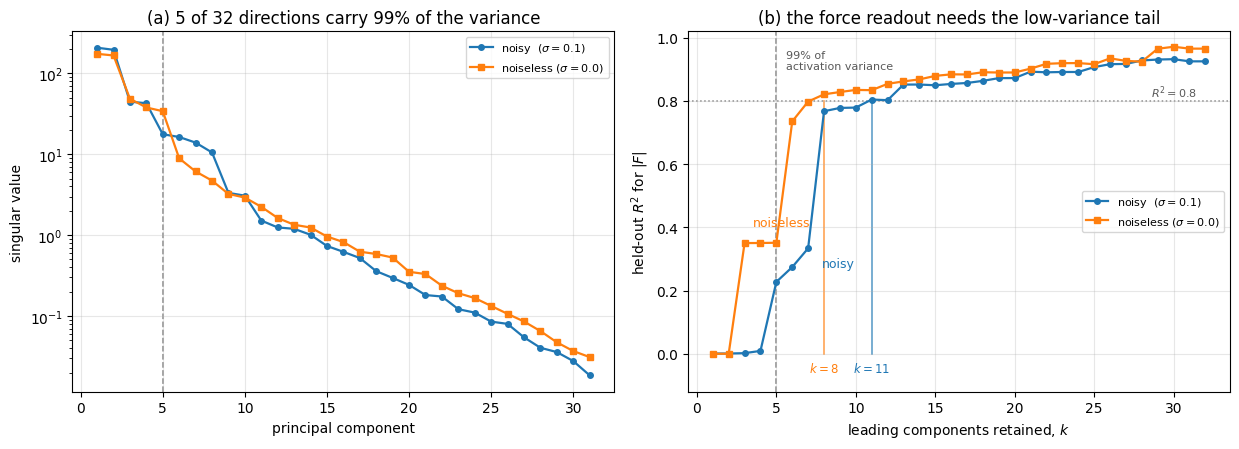

head reconstruction |W_head @ ln_f - prediction|, max: noisy 0.0e+00  noiseless 0.0e+00

  k  cum var % (noisy)  cum var % (noiseless)   R2 noisy   R2 noiseless
  1            50.0408                48.0503      0.001         -0.000
  2            94.4958                91.8897      0.001          0.000
  3            96.8128                95.6220      0.002          0.350
  4            98.9383                97.8911      0.009          0.351
  5            99.3020                99.7277      0.227          0.351
  6            99.6126                99.8530      0.274          0.735
  7            99.8382                99.9124      0.334          0.798
  8            99.9669                99.9478      0.767          0.821
 11            99.9935                99.9857      0.804          0.834
 16            99.9992                99.9978      0.854          0.884
 24           100.0000                99.9999      0.891          0.920
 32           100.0000               100.0000  

In [4]:
#| label: fig-supp-spectrum
#| fig-cap: "Where the force readout lives at the final layernorm, for the two context-2 models. (a) Singular values of the centred `ln_f` activations over 4,000 held-out windows. Both models put 99% of their variance in 5 of 32 directions and then decay smoothly over four orders of magnitude; a 32nd value at ~1e-13, omitted from the panel, is LayerNorm's mean-subtraction removing exactly one dimension. (b) Held-out probing R^2 for |F| from the top-k principal components only. Both models reach R^2 ~ 0.93-0.97 using everything, and the standard best-layer protocol cannot tell them apart (0.999 vs 1.000), but they get there differently: the noiseless model -- the one ELM shows is a genuine Verlet integrator -- has a third of the force available by k=3 and passes 0.8 at k=8, while the noisy circular-heuristic model is still at R^2 = 0.01 at k=4 and needs k=11. Across k=3..7 the gap runs +0.34 to +0.46. Dashed line: the 5 components carrying 99% of the activation variance."
#| code-fold: true
def sample_windows(n, seed=SEED, span=800):
    """n random two-position windows from trajectories the transformer never saw."""
    with contextlib.redirect_stdout(io.StringIO()):
        tr = np.asarray(load_trajectories(
            'data_cv', num_trajectories_needed=TEST_OFF + span))[TEST_OFF:]
    rg = np.random.default_rng(seed)
    ti, si = rg.integers(0, len(tr), n), rg.integers(0, 97, n)
    W   = np.stack([tr[t, s:s + 2] for t, s in zip(ti, si)])
    nxt = np.stack([tr[t, s + 2]   for t, s in zip(ti, si)])
    return W, nxt


def ln_f_activations(mdl, wnd):
    """Final-layernorm output at the last token: the only thing the output head reads."""
    rec = {}
    hk = mdl.transformer.ln_f.register_forward_hook(
        lambda m, i, o: rec.__setitem__('L', o.detach()[:, -1, :].double().clone()))
    try:
        with torch.no_grad():
            pred = mdl(torch.tensor(wnd).to(next(mdl.parameters()).dtype))[0][:, -1, :]
    finally:
        hk.remove()
    return rec['L'].numpy(), pred.double().numpy()


def spectrum_and_curve(mdl, wnd, y, itr, ite):
    """Singular values / cumulative variance of the centred ln_f activations, and
    held-out probe R^2 for `y` from the top-k principal components, for every k."""
    L, pred = ln_f_activations(mdl, wnd)
    head_err = np.abs(L @ mdl.output_head.weight.detach().double().numpy().T - pred).max()
    mu = L[itr].mean(0)
    _, S, Vt = np.linalg.svd(L[itr] - mu, full_matrices=False)
    P  = (L - mu) @ Vt.T
    r2 = np.array([
        r2_score(y[ite],
                 LinearRegression().fit(P[itr][:, :k], y[itr]).predict(P[ite][:, :k]))
        for k in range(1, L.shape[1] + 1)])
    return S, np.cumsum(S ** 2) / (S ** 2).sum(), r2, head_err


W_svd, _  = sample_windows(4000)
F_svd     = 1.0 / np.linalg.norm(W_svd[:, -1, :], axis=1) ** 2
i_tr, i_te = train_test_split(np.arange(len(W_svd)), test_size=0.5, random_state=0)

MODELS = [(r'noisy  ($\sigma=0.1$)',     0.1, 'tab:blue',   'o'),
          (r'noiseless ($\sigma=0.0$)',  0.0, 'tab:orange', 's')]
res = {lab: spectrum_and_curve(load(ns, 2), W_svd, F_svd, i_tr, i_te)
       for lab, ns, _, _ in MODELS}

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12.5, 4.6))
k99s = sorted({int(np.searchsorted(res[lab][1], 0.99) + 1) for lab, *_ in MODELS})
for ax in (axA, axB):
    for k in k99s:
        ax.axvline(k, color='0.55', ls='--', lw=1.1, zorder=0)
    ax.grid(alpha=0.3)
axB.axhline(0.8, color='0.55', ls=':', lw=1.1, zorder=0)

for lab, _, colour, marker in MODELS:
    S, cum, r2, _ = res[lab]
    ks   = np.arange(1, len(S) + 1)
    keep = S > S[0] * 1e-10          # drop LayerNorm's exact null direction (~1e-13)
    axA.semilogy(ks[keep], S[keep], marker + '-', color=colour, ms=4, lw=1.6, label=lab)
    axB.plot(ks, r2, marker + '-', color=colour, ms=4, lw=1.6, label=lab)
    # direct label each curve in clear space, away from the converged tail
    if colour == 'tab:blue':                    # noisy: below its curve at the widest gap
        klab, off, va = int(np.argmax(res[MODELS[1][0]][2] - res[MODELS[0][0]][2])) + 1, (10, -6), 'top'
    else:                                       # noiseless: above its first plateau
        klab, off, va = int(np.argmax(r2 >= 0.3)) + 1, (6, 10), 'bottom'
    axB.annotate(lab.split()[0], (klab, r2[klab - 1]), textcoords='offset points',
                 xytext=off, va=va, fontsize=9, color=colour, fontweight='medium')
    # how many components each needs before the readout is worth much
    k80 = int(np.argmax(r2 >= 0.8)) + 1
    axB.plot([k80, k80], [0.0, 0.8], color=colour, lw=1.2, alpha=0.7, zorder=0)
    axB.annotate(f'$k={k80}$', (k80, 0.0), textcoords='offset points',
                 xytext=(0, -13), ha='center', fontsize=8.5, color=colour)

axA.set_xlabel('principal component'); axA.set_ylabel('singular value')
axA.set_title('(a) 5 of 32 directions carry 99% of the variance')
axA.legend(fontsize=8)
axB.text(k99s[-1] + 0.6, 0.90, '99% of\nactivation variance', fontsize=8, color='0.35')
axB.text(31.5, 0.815, r'$R^2=0.8$', fontsize=8, color='0.35', ha='right')
axB.set_xlabel(r'leading components retained, $k$')
axB.set_ylabel(r'held-out $R^2$ for $|F|$')
axB.set_title(r'(b) the force readout needs the low-variance tail')
axB.set_ylim(-0.12, 1.02); axB.legend(fontsize=8, loc='center right')
fig.tight_layout(); plt.show()

print(f'head reconstruction |W_head @ ln_f - prediction|, max: '
      + '  '.join(f'{lab.split()[0]} {res[lab][3]:.1e}' for lab, *_ in MODELS))
print(f'\n{"k":>3} {"cum var % (noisy)":>18} {"cum var % (noiseless)":>22} '
      f'{"R2 noisy":>10} {"R2 noiseless":>14}')
lab_n, lab_l = MODELS[0][0], MODELS[1][0]
for k in [1, 2, 3, 4, 5, 6, 7, 8, 11, 16, 24, 32]:
    print(f'{k:3d} {100 * res[lab_n][1][k-1]:18.4f} {100 * res[lab_l][1][k-1]:22.4f} '
          f'{res[lab_n][2][k-1]:10.3f} {res[lab_l][2][k-1]:14.3f}')


Both models end up in the same place and get there differently. Using every
component the two are close (held-out $R^2$ 0.93 and 0.97) and the protocol the
main text replicates — best over thirteen sites, all 32 dimensions — reports 0.999
against 1.000, which is no difference at all. Restricted to the leading components,
they separate: the noiseless model has a third of $|F|$ readable from three
components and clears 0.8 at $k=8$, while the noisy model is at $R^2 = 0.01$
through $k=4$ and needs $k=11$. Over $k=3\ldots7$ the gap runs $+0.34$ to $+0.46$,
and the ordering matches the ELM verdict that only the noiseless model computes
with a force.

This is the mechanical reconciliation of a high $R^2$ with a model that is not
using force. Five directions carry 99% of the variance at `ln_f`; the probe reaches
its headline number by also reading directions two to four orders of magnitude
smaller, where the representation has almost no dynamic range. A least-squares
readout is free to do that — its weight norm is unbounded — and the fitted probe
takes the offer: 77% of the variance of its prediction comes from the 27 components
outside the 99% bulk, which between them carry 0.70% of the activation variance
(50% and 0.27% for the noiseless model).

Two limits on how far to read this. It is a difference of degree and not of kind:
the noiseless model, which does compute a force, also needs the tail to get past
$R^2 \approx 0.8$. And small variance does not by itself mean unused — the main
text's deviation from inertia is roughly $1/40$ of the prediction, so a subspace
carrying a few percent of the output could in principle hold the entire
gravitational kick. Establishing that it does not would need the bulk/tail split
of the output compared against the kick directly, which we have not done.


## 4. The probe direction is not actionable

The obvious next step is to intervene: add a multiple of the probe direction to
the residual stream and see whether the prediction moves as though gravity had
changed. That fails, and the reason is instructive.

The activations are close to degenerate. Ordinary least squares reaches its high
$R^2$ by placing very large weights on directions along which the data barely
varies, so the smallest intervention that moves the decoded value is far too
small to move anything else. Ridge regularisation buys a usable direction at the
cost of $R^2$.

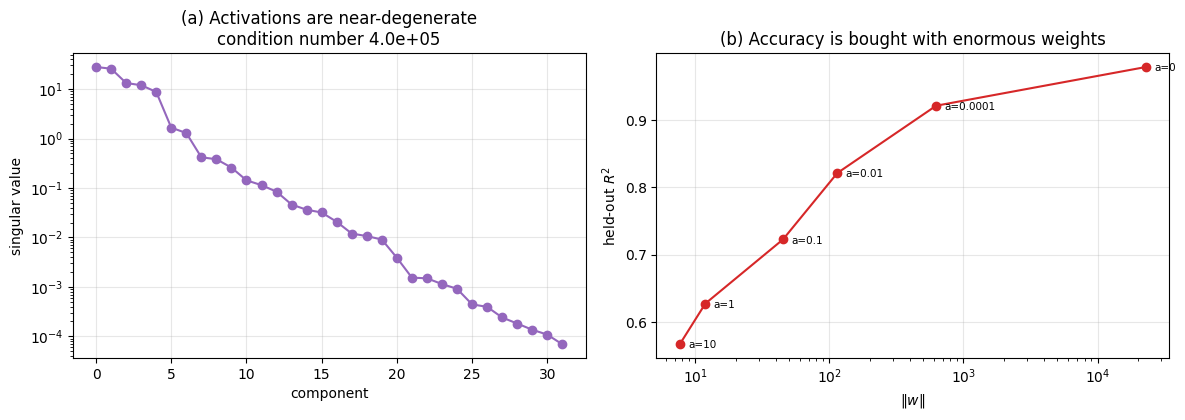

median activation norm            0.684
OLS ||w||                         22970
min-norm step to shift |F| by 0.62:  2.69e-05   (0.0039% of the activation norm)


In [5]:
#| label: fig-supp-conditioning
#| fig-cap: "Why the probe direction is hard to steer with. Left: singular values of the centred activations at the context-2 model's block-0 output; the top four directions carry most of the variance and the smallest are ~1e-4. Right: the ridge trade-off. OLS attains the highest R^2 with a weight vector of norm ~2e4, so the minimum-norm intervention that shifts the decoded |F| by one median is a perturbation of order 1e-5 against an activation norm of 0.68 - far too small to affect the model."
#| code-fold: true
def sample_windows(n, seed=SEED, span=800):
    with contextlib.redirect_stdout(io.StringIO()):
        tr = np.asarray(load_trajectories(
            'data_cv', num_trajectories_needed=TEST_OFF + span))[TEST_OFF:]
    rg = np.random.default_rng(seed)
    ti, si = rg.integers(0, len(tr), n), rg.integers(0, 97, n)
    W = np.stack([tr[t, s:s + 2] for t, s in zip(ti, si)])
    nxt = np.stack([tr[t, s + 2] for t, s in zip(ti, si)])
    return W, nxt

def record(mdl, W, module, steer=None):
    """Forward pass; optionally add `steer` to the last token of `module`'s output."""
    dt = next(mdl.parameters()).dtype
    Wt = torch.tensor(W).to(dt)
    handles, rec = [], {}
    if steer is not None:
        S = torch.tensor(steer).to(dt)
        handles.append(module.register_forward_hook(
            lambda m, i, o: torch.cat([o[:, :-1, :], o[:, -1:, :] + S.unsqueeze(1)], 1)))
    handles.append(module.register_forward_hook(
        lambda m, i, o: rec.__setitem__('h', o.detach()[:, -1, :].double().clone())))
    try:
        with torch.no_grad():
            pred = mdl(Wt)[0][:, -1, :].double().numpy()
    finally:
        for h in handles:
            h.remove()                      # never leave a steering hook attached
    return pred, rec['h'].numpy()

W, NXT = sample_windows(4000)   # 2000 leaves the multi-layer estimates in section 5 unstable
r_t = W[:, 1, :]
F   = 1.0 / np.linalg.norm(r_t, axis=1) ** 2          # |F| = 1/r^2
p0, H = record(mdl2, W, mdl2.transformer.h[0])
tr_i, te_i = train_test_split(np.arange(len(W)), test_size=0.5, random_state=0)

sv = np.linalg.svd(H - H.mean(0), compute_uv=False)
alphas = [0.0, 1e-4, 1e-2, 1e-1, 1.0, 10.0]
tradeoff = []
for a in alphas:
    mod = (LinearRegression() if a == 0 else Ridge(alpha=a)).fit(H[tr_i], F[tr_i])
    tradeoff.append((r2_score(F[te_i], mod.predict(H[te_i])), np.linalg.norm(mod.coef_)))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12, 4.3))
axA.semilogy(sv, 'o-', color='tab:purple')
axA.set_xlabel('component'); axA.set_ylabel('singular value')
axA.set_title(f'(a) Activations are near-degenerate\ncondition number {sv[0]/sv[-1]:.1e}')
axA.grid(alpha=0.3)
axB.plot([t[1] for t in tradeoff], [t[0] for t in tradeoff], 'o-', color='tab:red')
for a, (r2v, nw) in zip(alphas, tradeoff):
    axB.annotate(f'a={a:g}', (nw, r2v), textcoords='offset points',
                 xytext=(6, -3), fontsize=7.5)
axB.set_xscale('log'); axB.set_xlabel(r'$\|w\|$'); axB.set_ylabel(r'held-out $R^2$')
axB.set_title('(b) Accuracy is bought with enormous weights')
axB.grid(alpha=0.3)
fig.tight_layout(); plt.show()

nw_ols = tradeoff[0][1]
print(f'median activation norm            {np.median(np.linalg.norm(H, axis=1)):.3f}')
print(f'OLS ||w||                         {nw_ols:.0f}')
print(f'min-norm step to shift |F| by {np.median(F):.2f}:  {np.median(F)/nw_ols:.2e}'
      f'   ({100*np.median(F)/nw_ols/np.median(np.linalg.norm(H,axis=1)):.4f}% of the activation norm)')

## 5. The intervention propagates, but the output does not move

Dropping the minimum-norm calibration and simply stepping a fixed distance along
a well-conditioned direction, we can ask two questions at once: does the injected
change survive to the end of the network, and does the model's prediction care?

The direction is a difference of means between high- and low-force windows, fit
on a training half. Readouts are ridge probes, which matters — an OLS readout has
so much gain along near-null directions that it reports enormous "decoded"
changes for any perturbation at all, and is useless as an instrument here.

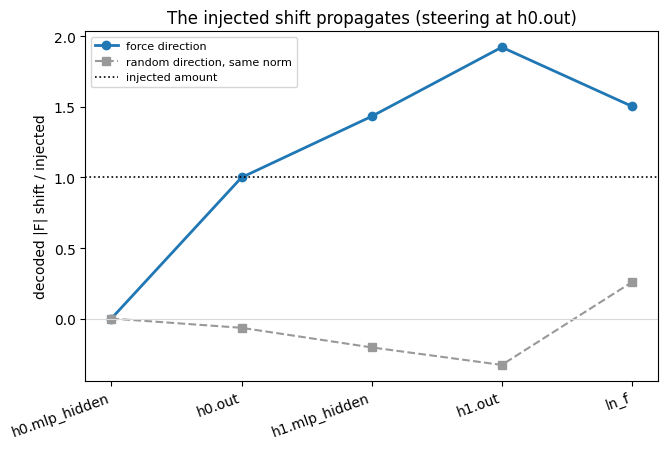

injected shift in decoded |F|      +0.619  (about one median, i.e. doubling it)
arriving at ln_f                   +0.931  (1.50x injected; random direction 0.26x)
change in prediction, force dir    0.0087  (15% of the model error)
change in prediction, random dir   0.0174  -> larger, but see the next section for why that comparison misleads


In [6]:
#| label: fig-supp-steering
#| fig-cap: "Propagation of the intervention. Steering along the force direction at the noisy model's block-0 output, the injected shift in decoded |F| survives to every downstream site and arrives at the final layernorm at about one and a half times its injected size, far above the level a random perturbation of the same norm produces. The manipulation is not absorbed, ignored, or recomputed away; whether the model's behaviour follows it is the subject of the next section."
#| code-fold: true
SITES = [('h0.mlp_hidden', mdl2.transformer.h[0].mlp.silu),
         ('h0.out',        mdl2.transformer.h[0]),
         ('h1.mlp_hidden', mdl2.transformer.h[1].mlp.silu),
         ('h1.out',        mdl2.transformer.h[1]),
         ('ln_f',          mdl2.transformer.ln_f)]

def all_sites(W, steer_mod=None, steer=None):
    dt = next(mdl2.parameters()).dtype
    Wt = torch.tensor(W).to(dt)
    handles, rec = [], {}
    if steer_mod is not None:
        S = torch.tensor(steer).to(dt)
        handles.append(steer_mod.register_forward_hook(
            lambda m, i, o: torch.cat([o[:, :-1, :], o[:, -1:, :] + S.unsqueeze(1)], 1)))
    for nm, mod in SITES:
        handles.append(mod.register_forward_hook(
            lambda m, i, o, nm=nm: rec.__setitem__(nm, o.detach()[:, -1, :].double().clone())))
    try:
        with torch.no_grad():
            pred = mdl2(Wt)[0][:, -1, :].double().numpy()
    finally:
        for h in handles:
            h.remove()
    return pred, {k: v.numpy() for k, v in rec.items()}

base_pred, base_act = all_sites(W)
err0 = np.median(np.linalg.norm(base_pred - NXT, axis=1)[te_i])

readout = {nm: Ridge(alpha=1.0).fit(base_act[nm][tr_i], F[tr_i]) for nm, _ in SITES}
decode  = lambda nm, A: readout[nm].predict(A)

STEER_AT = 'h0.out'
mod_by_name = dict(SITES)
Hs = base_act[STEER_AT]
hi = tr_i[F[tr_i] >= np.percentile(F[tr_i], 67)]
lo = tr_i[F[tr_i] <= np.percentile(F[tr_i], 33)]
d  = Hs[hi].mean(0) - Hs[lo].mean(0); dhat = d / np.linalg.norm(d)
TARGET = np.median(F)                                    # inject about +1 median |F|
step   = TARGET / (dhat @ readout[STEER_AT].coef_)
S      = np.tile(dhat * step, (len(W), 1))

rg   = np.random.default_rng(SEED)
Rdir = rg.normal(size=Hs.shape[1]); Rdir /= np.linalg.norm(Rdir)
Srnd = np.tile(Rdir * abs(step), (len(W), 1))

pS, aS = all_sites(W, mod_by_name[STEER_AT], S)
pR, aR = all_sites(W, mod_by_name[STEER_AT], Srnd)

names   = [nm for nm, _ in SITES]
through = [np.median(decode(nm, aS[nm])[te_i] - decode(nm, base_act[nm])[te_i]) / TARGET
           for nm in names]
rand_th = [np.median(decode(nm, aR[nm])[te_i] - decode(nm, base_act[nm])[te_i]) / TARGET
           for nm in names]
dS = np.median(np.linalg.norm((pS - base_pred)[te_i], axis=1))
dR = np.median(np.linalg.norm((pR - base_pred)[te_i], axis=1))

fig, axA = plt.subplots(figsize=(6.8, 4.6))
xs = np.arange(len(names))
axA.plot(xs, through, 'o-', lw=2, color='tab:blue', label='force direction')
axA.plot(xs, rand_th, 's--', lw=1.5, color='0.6', label='random direction, same norm')
axA.axhline(1, color='k', ls=':', lw=1.2, label='injected amount')
axA.axhline(0, color='0.85', lw=0.8)
axA.set_xticks(xs); axA.set_xticklabels(names, rotation=20, ha='right')
axA.set_ylabel('decoded |F| shift / injected')
axA.set_title(f'The injected shift propagates (steering at {STEER_AT})')
axA.legend(fontsize=8)
fig.tight_layout(); plt.show()

print(f'injected shift in decoded |F|      +{TARGET:.3f}  (about one median, i.e. doubling it)')
print(f'arriving at ln_f                   {through[-1]*TARGET:+.3f}  '
      f'({through[-1]:.2f}x injected; random direction {rand_th[-1]:.2f}x)')
print(f'change in prediction, force dir    {dS:.4f}  ({100*dS/err0:.0f}% of the model error)')
print(f'change in prediction, random dir   {dR:.4f}  '
      f'-> larger, but see the next section for why that comparison misleads')

The intervention is not absorbed, ignored, or recomputed away. A probe at the
final layernorm — the last thing before the output head — reads the altered force
at about one and a half times the injected size, while an equally large random
perturbation produces roughly a tenth of that. Whatever else is true, the
manipulation reaches the end of the network.

The prediction, meanwhile, moves by only a fraction of the model's own one-step
error, and by *less* than the random perturbation moves it. Read naively that
looks like a null: the feature is decodable and reachable, and the behaviour does
not follow. That reading is wrong, and the next section shows why.

## 6. Scoring against the counterfactual

The comparison in the previous section — how far the prediction moved, against how
far a random perturbation of the same norm moves it — is the wrong statistic, and
it points the wrong way. It rewards displacement magnitude and is completely blind
to whether the displacement goes anywhere sensible. Noise moves the prediction
further precisely because it can move it anywhere.

The right question, and the one Nanda et al. (2023) ask of the Othello board
state, is whether the output goes where the counterfactual says it should. Here
that target is exact. Raising the force to $k|F|$ is a well-defined change to the
physics — it is what a larger $GM$ would do — and a Newtonian integrator's
prediction would shift by

$$\Delta \hat{\mathbf r} \;=\; -\,\Delta t^{2}\,(k-1)\,F\,\hat{\mathbf r}_t$$

radially, toward the star for $k>1$ and away from it for $k<1$. The circular
heuristic gives a different and equally explicit target: unable to represent $GM$,
it can only read a larger force as a smaller radius, $r' = r k^{-1/2}$, and would
turn by $\Delta t / r'^{3/2}$ instead — a tangential move. Two candidate
counterfactuals.

Following Nanda et al., the intervention is applied to the residual stream at
*every* layer rather than at a single point — they report needing a sufficient
number of layers before OthelloGPT's predictions move at all, which they attribute
to the residual structure and to later layers repairing an upstream edit. This
model has only two layers to work with, and we skip the residual stream before
block 0, where $|F|$ is not linearly present at all (Section 2) and so there is no
direction to add.

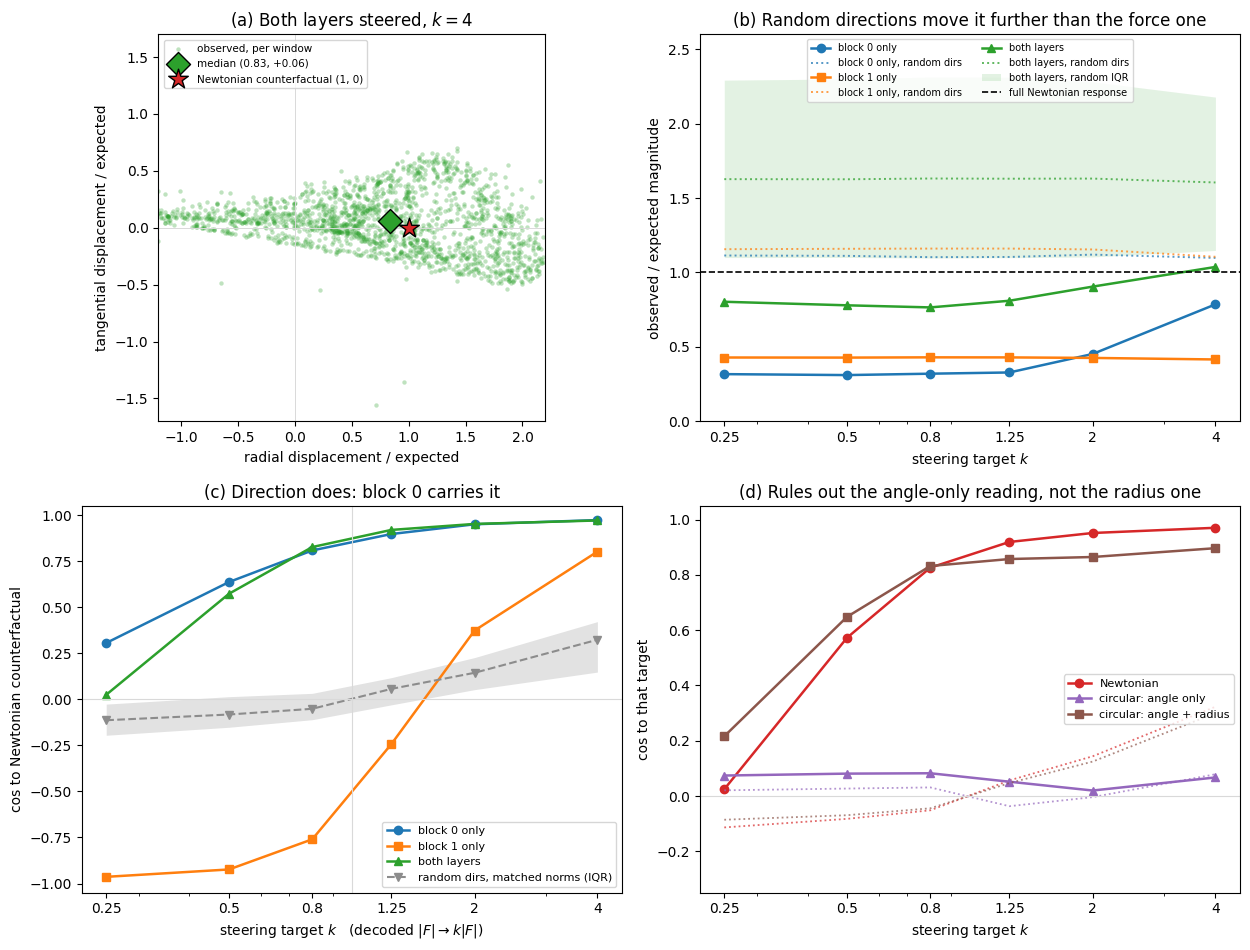

    k |          block 0 only |          block 1 only |           both layers |    random (both, 40 draws: median then IQR)
      |      frac        cos |      frac        cos |      frac        cos |      frac       cos
 0.25 |      0.32      +0.31 |      0.43      -0.96 |      0.80      +0.02 |      1.63      -0.11   [1.10,2.29] [-0.20,-0.03]
 0.50 |      0.31      +0.64 |      0.43      -0.92 |      0.78      +0.57 |      1.63      -0.08   [1.10,2.30] [-0.15,+0.01]
 0.80 |      0.32      +0.81 |      0.43      -0.76 |      0.76      +0.83 |      1.63      -0.05   [1.10,2.31] [-0.11,+0.03]
 1.25 |      0.33      +0.90 |      0.43      -0.24 |      0.81      +0.92 |      1.63      +0.06   [1.10,2.31] [-0.03,+0.12]
 2.00 |      0.45      +0.95 |      0.43      +0.37 |      0.90      +0.95 |      1.63      +0.14   [1.10,2.28] [+0.05,+0.23]
 4.00 |      0.79      +0.97 |      0.42      +0.80 |      1.04      +0.97 |      1.60      +0.32   [1.15,2.18] [+0.15,+0.42]


In [7]:
#| label: fig-supp-counterfactual
#| fig-cap: "Scoring the intervention against an explicit counterfactual, with the addition applied to the residual stream at every layer as in Nanda et al. (2023). If the decoded force is driven to k times its value and the model acted on it, a Newtonian integrator would shift its prediction by -dt^2 (k-1) F r-hat: radially, toward the star for k>1 and away for k<1. Dotted lines throughout are the same intervention with the force direction replaced by random directions of matched per-window norm, projected orthogonal to the force direction, median over 40 draws. (a) Per-window displacement with both layers steered at k=4, in units of the expected one, so the counterfactual is the point (1, 0). (b) Magnitude of the response, with the interquartile range over draws shaded for the both-layers control. Every steered curve falls below the corresponding random median, and the both-layers curve falls below the control's IQR: a random direction of the same norm moves the prediction further than the force direction does. The size of the response is set by the norm we injected, not by anything the model computes. (c) Direction, where the control sits near zero until the largest push and the force direction does not. At k = 0.25 the both-layers response is at the control; block 0 alone is not. Block 0 carries the effect; block 1 alone is unreliable, its alignment varying from 0.06 to 0.80 across resamples. (d) Alignment against each candidate target. The response is radial, which rules out the angle-only reading of the circular heuristic, but the Newtonian kick and the radius-reassignment reading are both radial and the intervention cannot separate them."
#| code-fold: true
KS = [0.25, 0.5, 0.8, 1.25, 2.0, 4.0]
# Residual-stream points, one per layer.  The pre-block-0 residual is omitted:
# |F| is not linearly present before the first MLP (R^2 ~ -0.01 above), so there
# is no force direction there to add.
RESID = [('block 0', mdl2.transformer.h[0]), ('block 1', mdl2.transformer.h[1])]
CONDS = [('block 0 only', ['block 0'], 'tab:blue',  'o'),
         ('block 1 only', ['block 1'], 'tab:orange','s'),
         ('both layers',  ['block 0', 'block 1'], 'tab:green', '^')]
RSEEDS = range(40)      # the control's spread across draws is wide; 3 draws badly misestimates it
_MDT = next(mdl2.parameters()).dtype

def run_multi(steers=None):
    """Forward pass, adding `steers[name]` to the last token of each named layer."""
    handles, rec = [], {}
    for nm, mod in RESID:
        if steers and nm in steers:
            S = torch.tensor(steers[nm]).to(_MDT)
            handles.append(mod.register_forward_hook(
                lambda m, i, o, S=S: torch.cat([o[:, :-1, :], o[:, -1:, :] + S.unsqueeze(1)], 1)))
        handles.append(mod.register_forward_hook(
            lambda m, i, o, nm=nm: rec.__setitem__(nm, o.detach()[:, -1, :].double().clone())))
    try:
        with torch.no_grad():
            pred = mdl2(torch.tensor(W).to(_MDT))[0][:, -1, :].double().numpy()
    finally:
        for h in handles:
            h.remove()
    return pred, {k: v.numpy() for k, v in rec.items()}

base_ml, act_ml = run_multi()
force_dir = {}
for nm, _ in RESID:                                  # direction + gain, train half only
    H  = act_ml[nm]
    rd = Ridge(alpha=1.0).fit(H[tr_i], F[tr_i])
    hi = tr_i[F[tr_i] >= np.percentile(F[tr_i], 67)]
    lo = tr_i[F[tr_i] <= np.percentile(F[tr_i], 33)]
    d  = H[hi].mean(0) - H[lo].mean(0); dh = d / np.linalg.norm(d)
    force_dir[nm] = (dh, dh @ rd.coef_, rd.predict(H))

def steer_vecs(active, k):
    """Per-window additions that drive the decoded |F| to k times its value."""
    S = {}
    for nm in active:
        dh, gain, fhat = force_dir[nm]
        S[nm] = ((k - 1.0) * fhat / gain)[:, None] * dh[None, :]
    return S

_cache = {}
def response(active, k, seed=None):
    """Change in prediction. seed=None steers along the force direction; an int
    replaces it with a random direction of the same per-window norm."""
    key = (tuple(active), k, seed)
    if key not in _cache:
        S = steer_vecs(active, k)
        if seed is not None:
            rng = np.random.default_rng(seed)
            for nm in S:
                # project out the force direction: in d_model = 32 an isotropic draw
                # overlaps it with sd 0.18, which would leak real steering into the null
                dh = force_dir[nm][0]
                R = rng.normal(size=S[nm].shape[1]); R -= (R @ dh) * dh
                R /= np.linalg.norm(R)
                S[nm] = np.linalg.norm(S[nm], axis=1)[:, None] * R[None, :]
        _cache[key] = run_multi(S)[0] - base_ml
    return _cache[key]

rad_  = np.linalg.norm(r_t, axis=1)
ghat  = -r_t / rad_[:, None]
that_ = np.stack([-ghat[:, 1], ghat[:, 0]], axis=1)
sgn   = np.sign(np.median(np.arctan2(r_t[:, 0] * base_ml[:, 1] - r_t[:, 1] * base_ml[:, 0],
                                     (r_t * base_ml).sum(1))))

def targets(k):
    """Newtonian, and the two readings of the circular heuristic."""
    newt  = -(DT_SUPP ** 2 * (k - 1.0) * F)[:, None] * (r_t / rad_[:, None])
    r_new = rad_ * k ** -0.5                      # the radius a larger |F| implies
    dth   = sgn * DT_SUPP * (r_new ** -1.5 - rad_ ** -1.5)
    c, s_ = np.cos(dth), np.sin(dth)
    rot   = lambda v: np.stack([v[:, 0] * c - v[:, 1] * s_, v[:, 0] * s_ + v[:, 1] * c], 1)
    return newt, rot(r_t) - r_t, rot(r_t * (r_new / rad_)[:, None]) - r_t

def cosmed(o, t):
    no, nt = np.linalg.norm(o, axis=1), np.linalg.norm(t, axis=1)
    return float(np.median(((o * t).sum(1) / (no * nt + 1e-30))[te_i]))
def fracmed(o, t):
    no, nt = np.linalg.norm(o, axis=1), np.linalg.norm(t, axis=1)
    return float(np.median((no / (nt + 1e-30))[te_i]))
def ctrl(stat, active, k, j=0):
    """Same statistic under matched-norm random directions: median and IQR."""
    v = [stat(response(active, k, s), targets(k)[j]) for s in RSEEDS]
    return float(np.median(v)), float(np.percentile(v, 25)), float(np.percentile(v, 75))

fig, ax = plt.subplots(2, 2, figsize=(12.6, 9.6))

# (a) where the prediction goes, in units of the expected displacement -------------
A = ax[0, 0]; k = 4.0
obs = response(['block 0', 'block 1'], k); newt = targets(k)[0]
nt = np.linalg.norm(newt, axis=1)
xr, yt = (obs * ghat).sum(1) / nt, (obs * that_).sum(1) / nt
A.scatter(xr[te_i], yt[te_i], s=10, alpha=0.30, color='tab:green', linewidths=0,
          label='observed, per window')
A.scatter([np.median(xr[te_i])], [np.median(yt[te_i])], s=150, marker='D', color='tab:green',
          edgecolor='k', zorder=5,
          label=f'median ({np.median(xr[te_i]):.2f}, {np.median(yt[te_i]):+.2f})')
A.scatter([1], [0], s=220, marker='*', color='tab:red', edgecolor='k', zorder=6,
          label='Newtonian counterfactual (1, 0)')
A.axhline(0, color='0.85', lw=0.7); A.axvline(0, color='0.85', lw=0.7)
A.set_xlim(-1.2, 2.2); A.set_ylim(-1.7, 1.7); A.set_aspect('equal')
A.set_xlabel('radial displacement / expected'); A.set_ylabel('tangential displacement / expected')
A.set_title(f'(a) Both layers steered, $k={k:g}$'); A.legend(fontsize=7.5, loc='upper left')

# (b) magnitude -- and the control matches it ---------------------------------------
B = ax[0, 1]
for label, active, colour, marker in CONDS:
    B.plot(KS, [fracmed(response(active, k), targets(k)[0]) for k in KS],
           marker + '-', color=colour, lw=1.8, label=label)
    cc = [ctrl(fracmed, active, k) for k in KS]
    B.plot(KS, [c[0] for c in cc], ls=':', color=colour, lw=1.4, alpha=0.75,
           label=f'{label}, random dirs')
    if label == 'both layers':
        B.fill_between(KS, [c[1] for c in cc], [c[2] for c in cc], color=colour, alpha=0.13, lw=0,
                       label='both layers, random IQR')
B.axhline(1, color='k', ls='--', lw=1.2, label='full Newtonian response')
B.set_xscale('log'); B.set_xticks(KS); B.set_xticklabels([f'{k:g}' for k in KS])
B.set_ylim(0, 2.6); B.set_xlabel(r'steering target $k$')
B.set_ylabel('observed / expected magnitude')
B.set_title('(b) Random directions move it further than the force one'); B.legend(fontsize=7, ncol=2)

# (c) direction -- here the control is flat -----------------------------------------
C = ax[1, 0]
for label, active, colour, marker in CONDS:
    C.plot(KS, [cosmed(response(active, k), targets(k)[0]) for k in KS],
           marker + '-', color=colour, lw=1.8, label=label)
cc = [ctrl(cosmed, ['block 0', 'block 1'], k) for k in KS]
C.plot(KS, [c[0] for c in cc], 'v--', color='0.55', lw=1.5, label='random dirs, matched norms (IQR)')
C.fill_between(KS, [c[1] for c in cc], [c[2] for c in cc], color='0.55', alpha=0.25, lw=0)
C.axhline(0, color='0.85', lw=0.8); C.axvline(1, color='0.85', lw=0.8)
C.set_xscale('log'); C.set_xticks(KS); C.set_xticklabels([f'{k:g}' for k in KS])
C.set_ylim(-1.05, 1.05); C.set_xlabel(r'steering target $k$   (decoded $|F| \to k|F|$)')
C.set_ylabel('cos to Newtonian counterfactual')
C.set_title('(c) Direction does: block 0 carries it'); C.legend(fontsize=8, loc='lower right')

# (d) direction against each candidate target ---------------------------------------
D = ax[1, 1]
for j, (lab, colour, marker) in enumerate([('Newtonian', 'tab:red', 'o'),
                                           ('circular: angle only', 'tab:purple', '^'),
                                           ('circular: angle + radius', 'tab:brown', 's')]):
    D.plot(KS, [cosmed(response(['block 0', 'block 1'], k), targets(k)[j]) for k in KS],
           marker + '-', color=colour, lw=1.8, label=lab)
    cc = [ctrl(cosmed, ['block 0', 'block 1'], k, j) for k in KS]
    D.plot(KS, [c[0] for c in cc], ls=':', color=colour, lw=1.3, alpha=0.7)
D.axhline(0, color='0.85', lw=0.8)
D.set_xscale('log'); D.set_xticks(KS); D.set_xticklabels([f'{k:g}' for k in KS])
D.set_ylim(-0.35, 1.05); D.set_xlabel(r'steering target $k$')
D.set_ylabel('cos to that target')
D.set_title('(d) Rules out the angle-only reading, not the radius one')
D.legend(fontsize=8, loc='center right')
fig.tight_layout(); plt.show()

print(f'{"k":>5} | ' + ' | '.join(f'{lab:>21s}' for lab, *_ in CONDS) + ' |    random (both, 40 draws: median then IQR)')
print(f'{"":>5} | ' + ' | '.join(f'{"frac":>9s} {"cos":>10s}' for _ in CONDS) + ' |      frac       cos')
for k in KS:
    row = f'{k:5.2f} | '
    for _, active, _, _ in CONDS:
        o, t = response(active, k), targets(k)[0]
        row += f'{fracmed(o, t):9.2f} {cosmed(o, t):+10.2f} | '
    rf = ctrl(fracmed, ['block 0', 'block 1'], k); rc = ctrl(cosmed, ['block 0', 'block 1'], k)
    print(row + f'{rf[0]:9.2f} {rc[0]:+10.2f}   [{rf[1]:.2f},{rf[2]:.2f}] [{rc[1]:+.2f},{rc[2]:+.2f}]')

Judged this way the intervention works, in the sense that usually counts. The
prediction moves along the Newtonian counterfactual at cosine $+0.97$, while
random directions of matched norm sit at zero. The decoded direction is causally
efficacious and the effect is specific to it. Steering block 0 alone gets most of
the way there; adding block 1 completes it, the pattern Nanda et al. describe
where a single site is not enough.

And it still cannot tell us what the model computes.

The magnitude does worse than no work. A random direction of the same per-window
norm moves the prediction *further*: median $1.63$ times the Newtonian
displacement across 40 draws, interquartile range $[1.10, 2.31]$, against $0.81$
for the force direction, which falls below that range. So the force direction is
a comparatively low-gain direction, and the fact that the steered response lands
near $1$ against the Newtonian target is a coincidence of scale — well inside
what an arbitrary direction of the same norm produces. The size of the response
is set by how hard we pushed, not by an internal law, so "the response is
Newtonian-sized" says nothing. Only the direction is informative.

This also disposes of the comparison the previous section flagged. Judging a
steering result by how far the output moved, against a random-perturbation
floor, would reject this intervention — and judging it by direction accepts it.
The two criteria disagree, and only the second is measuring anything about the
model.

The direction, in turn, only half-discriminates. It rules out reading the
circular heuristic as a pure angle change: that target is tangential and the
observed response is radial, cosine $+0.07$. But the other reading of the same
heuristic — inflating $|F|$ means asserting a smaller radius, so move the
prediction inward and rotate — is radial too, and scores $+0.90$ against the
Newtonian target's $+0.97$. The two hypotheses this experiment was built to
separate produce nearly the same signature, and the statistic that would
separate them is the one the control just invalidated.

So the intervention passes every check normally offered as evidence that a probe
direction reflects mechanism, and leaves the mechanistic question where it found
it. That is the point. The ELM analysis in the main text does settle it, and it
settles it against the force reading.

Three further qualifications.

Reducing gravity barely works at all. At $k = 0.25$ the both-layers response
reaches cosine $+0.02$ against a control median of $-0.11$ — no better than an
arbitrary direction. Curiously block 0 alone does reach $+0.31$ there, so
recruiting the second layer *costs* alignment at the reduction end while gaining
it at the other.

Block 1 on its own is not a usable handle. Across resamples its alignment ranges
from $+0.06$ to $+0.80$ and its magnitude from $0.42$ to $1.69$, so its direction
estimate is poorly determined. It contributes only in combination with block 0.

The response is not symmetric in $k$. Turning gravity *up* gives strong alignment,
stable across resamples. Turning it *down* gives weaker alignment that is also
unstable: repeated draws put the $k = 0.25$ value anywhere from $+0.06$ to $+0.45$.
The obvious mechanical explanation does not hold — the downstream SiLU is never
driven into its flat region by these interventions (0.00% of hidden units below
$-2$ at every $k$), and the steered activations stay within the observed range of
the natural projections, so this is neither rectification at a nonlinearity nor a
manifold boundary. We have no account of it.

At the largest push the control stops being clean. By $k = 4$ the matched random
directions reach cosine $+0.32$ on their own (IQR $[+0.15, +0.42]$), and this is
not probe leakage — the control is projected orthogonal to the force direction,
and leaving it isotropic gives $+0.31$ instead — so some of the alignment at that
end of the sweep is a generic consequence of perturbing the residual stream hard.
The gap to $+0.97$ is still wide, and at moderate $k$ the control is at zero, but
the $k = 4$ column should not be read as if the baseline were still zero there.